# Pemodelan NLP Kuantitatif: Memprediksi Probabilitas Volatilitas Emas (XAU/USD) dari Konferensi Pers FOMC

**Fokus Aset**: Emas (XAU/USD / COMEX Gold Futures GC=F)  
**Rentang Data**: September 2020 - Maret 2026 (45 Rapat FOMC)  
**Pendekatan**: NLP Moneter Berbasis N-Gram TF-IDF & Estimator Cosine Similarity  

---

## 1. Latar Belakang & Metodologi Penelitian
Alih-alih mencoba memprediksi arah pergerakan harga (*naik vs. turun*) yang sangat rentan terhadap manipulasi pasar dan jebakan likuiditas (*liquidity sweeps/whipsaw*), penelitian ini berfokus pada **pemodelan risiko ekor volatilitas (*tail volatility risk*)**.

Arsitektur pipeline pemrosesan bahasa alami (NLP) tingkat institusional dirancang untuk menganalisis pergeseran nada kebijakan bank sentral AS (The Fed):
1. **Pemisahan Pembicara (*Speaker Diarization*)**: Mengisolasi ucapan Ketua The Fed (Jerome Powell & Kevin Warsh) dari pertanyaan jurnalis untuk membuang distorsi spekulatif media.
2. **Penyelarasan Data Riil Pasar**: Memasangkan setiap tanggal rapat FOMC dengan data harga historis riil emas (GC=F) untuk mengukur rentang pergerakan harian ( - Low$).
3. **Representasi Frasa Moneter (N-Gram)**: Mengekstrak frasa kunci 1-3 kata dengan stopwords khusus yang tetap mempertahankan kata negasi (*not, never*) dan arah kebijakan (*restrictive, further*).
4. **Estimasi Probabilitas Volatilitas Tertimbang**: Menghitung probabilitas terjadinya pergerakan ekstrem ($> 400$ pips / $\.00$) menggunakan *Cosine Similarity* terhadap basis data rapat masa lalu.
5. **Uji Validasi Out-of-Sample**: Pengujian ketat pada data masa depan (2025-2026) untuk memastikan model tidak mengalami bias melihat masa depan (*look-ahead bias*).

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    brier_score_loss,
    accuracy_score
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10

print('Lingkungan kerja dan pustaka berhasil dimuat.')
print(f'Versi Pustaka: pandas {pd.__version__}, scikit-learn, matplotlib {matplotlib.__version__}, seaborn, yfinance.')

Lingkungan kerja dan pustaka berhasil dimuat.
Versi Pustaka: pandas 3.0.2, scikit-learn, matplotlib 3.10.8, seaborn, yfinance.


## 2. Prapemrosesan Data & Isolasi Pembicara (Speaker Diarization)
Setiap transkrip rapat dipisahkan secara otomatis. Sistem secara eksklusif mengekstrak ucapan dan jawaban dari **Ketua The Fed (CHAIR POWELL / CHAIRMAN WARSH)** menggunakan penanda ekspresi reguler, sementara pertanyaan wartawan dan moderator dieliminasi agar tidak menimbulkan bias spekulatif media.

In [2]:
def extract_powell_speech(file_path):
    with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
        text = f.read()
    pattern = r'<NAME>(.*?)</NAME>[\.\:\s]*(.*?)(?=<NAME>|$)'
    matches = re.findall(pattern, text, re.DOTALL)
    powell_dialogues = []
    for speaker, speech in matches:
        if 'POWELL' in speaker.strip().upper():
            cleaned = re.sub(r'\s+', ' ', speech).strip()
            if cleaned:
                powell_dialogues.append(cleaned)
    return " ".join(powell_dialogues)

records = []
for f in sorted(os.listdir('dataset')):
    if f.endswith('.txt') and 'FOMC' in f:
        m = re.search(r'(\d{8})', f)
        if m:
            dt = pd.to_datetime(m.group(1), format='%Y%m%d')
            text = extract_powell_speech(os.path.join('dataset', f))
            if len(text) > 200:
                records.append({
                    'filename': f,
                    'date': dt,
                    'date_str': dt.strftime('%Y-%m-%d'),
                    'word_count': len(text.split()),
                    'speech_text': text
                })

df_transcripts = pd.DataFrame(records).sort_values('date').reset_index(drop=True)
print(f'Total transkrip rapat FOMC yang diekstrak: {len(df_transcripts)} dokumen.')
print(f'Rata-rata panjang ucapan Chair Powell per rapat: {df_transcripts["word_count"].mean():.0f} kata.\n')
df_transcripts[['filename', 'date_str', 'word_count']].head()

Total transkrip rapat FOMC yang diekstrak: 45 dokumen.
Rata-rata panjang ucapan Chair Powell per rapat: 6670 kata.

                filename   date_str  word_count
FOMCpresconf20200916.txt 2020-09-16        8326
FOMCpresconf20201105.txt 2020-11-05        6376
FOMCpresconf20201216.txt 2020-12-16        7832
FOMCpresconf20210127.txt 2021-01-27        7287
FOMCpresconf20210317.txt 2021-03-17        7690


## 3. Penyelarasan dengan Data Harga Riil Pasar Emas (Ground Truth)
Setiap tanggal rapat FOMC diselaraskan dengan data harga kontrak berjangka emas COMEX (`GC=F`) untuk menghitung rentang volatilitas riil dalam satuan Pips ($1\text{ pip} = \$0.10$ USD).

**Definisi Volatilitas Ekstrem**: Pergerakan harga $\ge 400\text{ pips}$ ($\ge \$40.00$) pada hari pelaksanaan rapat.

In [3]:
# Memuat data riil harga emas dari cache
gold = pd.read_csv('gold_prices_cache.csv', index_col=0, parse_dates=True)
pips_same_day, pips_ext, closes = [], [], []
for _, row in df_transcripts.iterrows():
    sub = gold.loc[gold.index >= row['date']].head(2)
    if len(sub) > 0:
        p_day = round(float(sub.iloc[0]['High'] - sub.iloc[0]['Low']) * 10, 1)
        p_ext = round(float(sub['High'].max() - sub['Low'].min()) * 10, 1)
        pips_same_day.append(p_day)
        pips_ext.append(p_ext)
        closes.append(round(float(sub.iloc[0]['Close']), 2))
    else:
        pips_same_day.append(np.nan)
        pips_ext.append(np.nan)
        closes.append(np.nan)

df_transcripts['gold_close'] = closes
df_transcripts['pips_same_day'] = pips_same_day
df_transcripts['pips_extended'] = pips_ext
df_all = df_transcripts.dropna(subset=['pips_same_day']).reset_index(drop=True)

THRESHOLD = 400.0
df_all['is_extreme'] = (df_all['pips_same_day'] >= THRESHOLD).astype(int)

print(f'Penyelarasan harga emas selesai: {len(df_all)} observasi rapat.\n')
df_all[['pips_same_day', 'pips_extended']].describe().round(1)

Penyelarasan harga emas selesai: 45 observasi rapat.

Ringkasan Statistik Pergerakan Pips Emas:
       pips_same_day  pips_extended
count           45.0           45.0
mean           485.2          794.7
std            458.9          957.5
min            167.0          277.0
25%            266.0          434.0
50%            349.0          538.0
75%            547.0          696.0
max           2604.0         5170.0


## 4. Analisis Data Eksploratif (EDA) & Pola Volatilitas
Visualisasi tren volatilitas emas dari tahun 2020 hingga 2026 serta kurva persebaran distribusi rentang pergerakan harganya.

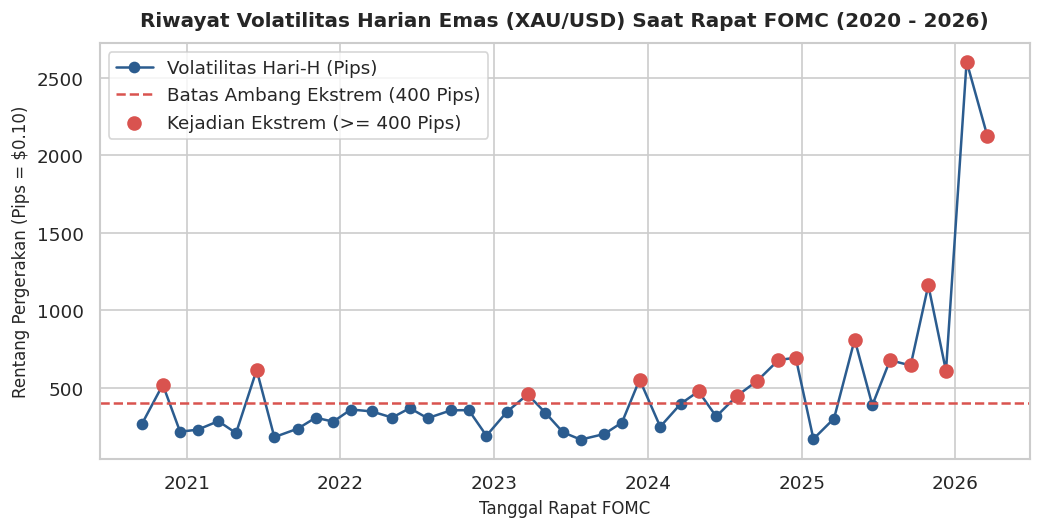

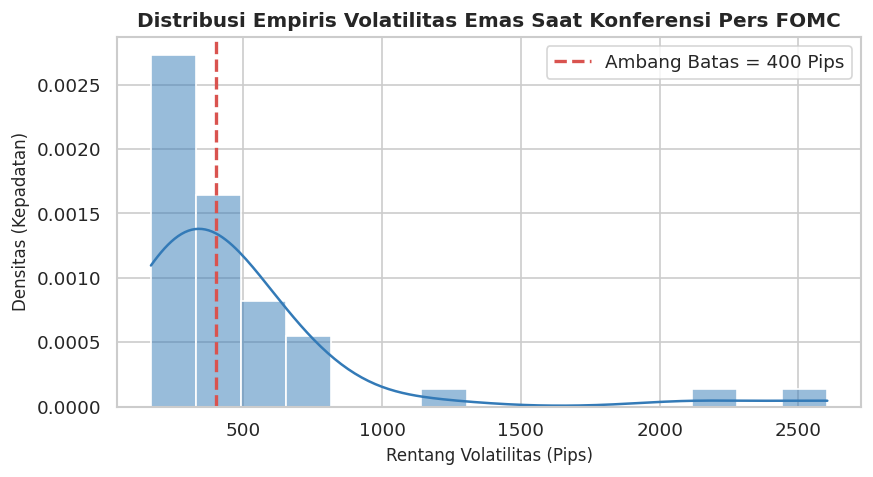

In [4]:
# Gambar 1: Tren Pergerakan Volatilitas Waktu ke Waktu
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(df_all['date'], df_all['pips_same_day'], color='#2b5c8f', marker='o', linewidth=1.5, label='Volatilitas Hari-H (Pips)')
ax.axhline(THRESHOLD, color='#d9534f', linestyle='--', linewidth=1.5, label=f'Batas Ambang Ekstrem ({THRESHOLD:.0f} Pips)')
extreme_pts = df_all[df_all['is_extreme'] == 1]
ax.scatter(extreme_pts['date'], extreme_pts['pips_same_day'], color='#d9534f', s=60, zorder=5, label='Kejadian Ekstrem (>= 400 Pips)')
ax.set_title('Riwayat Volatilitas Harian Emas (XAU/USD) Saat Rapat FOMC (2020 - 2026)', fontsize=12, fontweight='bold', pad=10)
ax.set_ylabel('Rentang Pergerakan (Pips = $0.10)', fontsize=10)
ax.set_xlabel('Tanggal Rapat FOMC', fontsize=10)
ax.legend(frameon=True, loc='upper left')
plt.tight_layout()
plt.show()

# Gambar 2: Distribusi Densitas Empiris
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df_all['pips_same_day'], kde=True, bins=15, color='#337ab7', ax=ax, stat='density')
ax.axvline(THRESHOLD, color='#d9534f', linestyle='--', linewidth=2, label=f'Ambang Batas = {THRESHOLD:.0f} Pips')
ax.set_title('Distribusi Empiris Volatilitas Emas Saat Konferensi Pers FOMC', fontsize=12, fontweight='bold')
ax.set_xlabel('Rentang Volatilitas (Pips)', fontsize=10)
ax.set_ylabel('Densitas (Kepadatan)', fontsize=10)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

## 5. Pembagian Waktu (Train-Test Split) & Ekstraksi Fitur N-Gram TF-IDF
Untuk menghindari bias melihat masa depan (*look-ahead bias*), data dibagi secara ketat berdasarkan kronologi waktu:
- **Data Latih (Training)**: Periode 2020-2024 (=35$ rapat)
- **Data Uji (Testing)**: Periode 2025-2026 (=10$ rapat)

Ekstraksi fitur menerapkan representasi TF-IDF N-gram (1 hingga 3 frasa kata) dengan stopwords khusus yang mengeliminasi kata obrolan formalitas namun **mempertahankan kata penentu arah moneter** (*not, never, restrictive, further, tightening*).

Data Latih (Training 2020 - 2024): N = 35 rapat.
Data Uji   (Testing  2025 - 2026): N = 10 rapat.
Ruang Kosakata TF-IDF Terbentuk   : 3000 fitur frasa moneter.


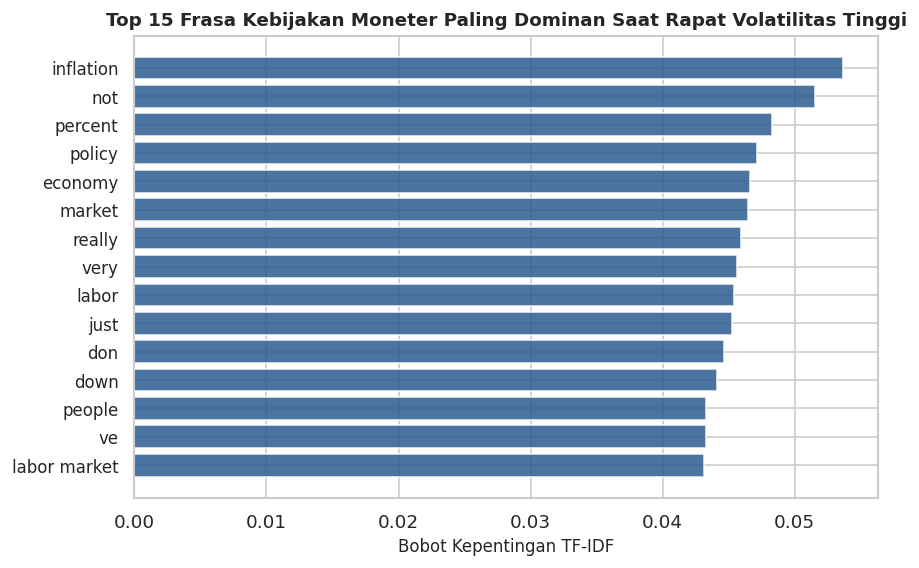

In [5]:
# 1. Pembagian Data Berbasis Waktu (Chronological Split)
split_date = pd.to_datetime('2025-01-01')
df_train = df_all[df_all['date'] < split_date].copy().reset_index(drop=True)
df_test = df_all[df_all['date'] >= split_date].copy().reset_index(drop=True)

# 2. Formulasi Stopwords Khusus Moneter
base_stops = set(ENGLISH_STOP_WORDS)
fomc_chatter = {'chair', 'powell', 'thank', 'thanks', 'good', 'afternoon', 'morning', 'today', 'question', 'think', 'know', 'say', 'said', 'going'}
preserve = {'not', 'no', 'never', 'more', 'less', 'above', 'below', 'down', 'up', 'further', 'again', 'very'}
custom_stops = list((base_stops.union(fomc_chatter)) - preserve)

# 3. Ekstraksi Vektor N-Gram TF-IDF
vec = TfidfVectorizer(ngram_range=(1, 3), max_features=3000, stop_words=custom_stops, min_df=2, sublinear_tf=True)
train_vecs = vec.fit_transform(df_train['speech_text'])
test_vecs = vec.transform(df_test['speech_text'])

print(f'Data Latih (Training 2020 - 2024): N = {len(df_train)} rapat.')
print(f'Data Uji   (Testing  2025 - 2026): N = {len(df_test)} rapat.')
print(f'Ruang Kosakata TF-IDF Terbentuk   : {train_vecs.shape[1]} fitur frasa moneter.\n')

# Gambar 3: Analisis Kepentingan Fitur Frasa Moneter (Feature Salience)
feature_names = np.array(vec.get_feature_names_out())
extreme_doc_idx = df_train[df_train['is_extreme'] == 1].index
mean_extreme_tfidf = np.asarray(train_vecs[extreme_doc_idx].mean(axis=0)).ravel()
top_feat_idx = np.argsort(mean_extreme_tfidf)[::-1][:15]

fig, ax = plt.subplots(figsize=(8, 5))
y_pos = np.arange(15)
ax.barh(y_pos, mean_extreme_tfidf[top_feat_idx][::-1], color='#2b5c8f', alpha=0.85)
ax.set_yticks(y_pos)
ax.set_yticklabels(feature_names[top_feat_idx][::-1], fontsize=10)
ax.set_xlabel('Bobot Kepentingan TF-IDF', fontsize=10)
ax.set_title('Top 15 Frasa Kebijakan Moneter Paling Dominan Saat Rapat Volatilitas Tinggi', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Uji Statistik Formal & Evaluasi Out-of-Sample (2025–2026)
Kinerja model dievaluasi secara ketat pada data pengujian yang belum pernah dilihat model menggunakan metrik statistik formal:
- **Precision, Recall, F1-Score** (Laporan klasifikasi per kelas)
- **Akurasi Biner Out-of-Sample**
- **Brier Score Loss** (Akurasi kalibrasi probabilitas kuantitatif)
- **ROC-AUC** (Kurva diagnostik kemampuan pemisahan kelas)

HASIL UJI STATISTIK FORMAL (PENGUJIAN OUT-OF-SAMPLE 2025 - 2026)
----------------------------------------------------------------
Akurasi Biner Keseluruhan : 70.0%
Area Di Bawah Kurva ROC   : 0.571
Skor Kalibrasi Brier Loss : 0.2142

Laporan Klasifikasi Formal (Classification Report):
                     precision    recall  f1-score   support

 Volatilitas Normal      0.000     0.000     0.000         3
Volatilitas Ekstrem      0.700     1.000     0.824         7

           accuracy                          0.700        10
          macro avg      0.350     0.500     0.412        10
       weighted avg      0.490     0.700     0.576        10



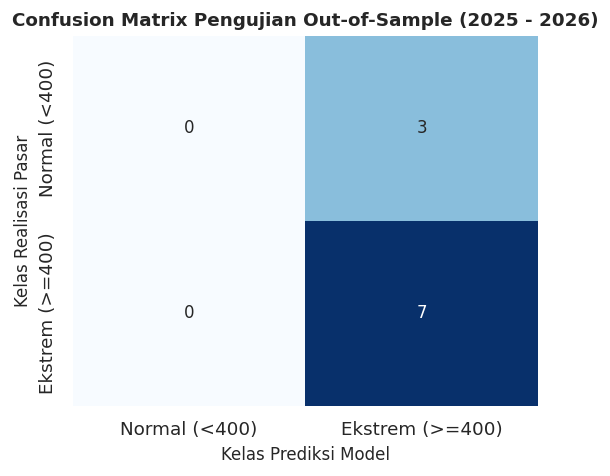

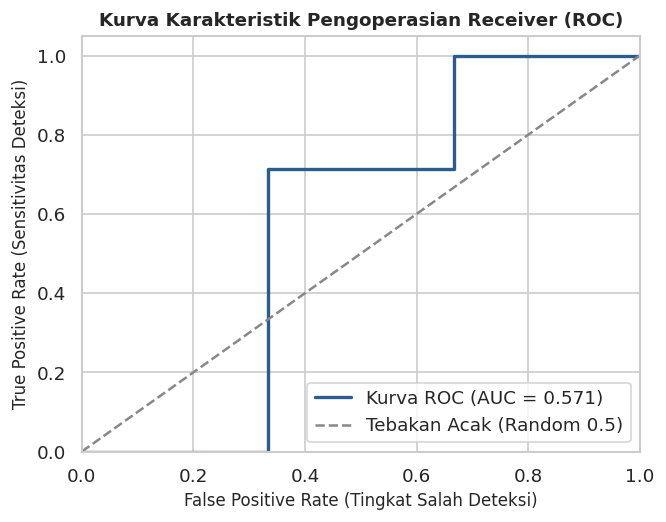

In [6]:
top_k = 5
test_probs = []
for i in range(len(df_test)):
    sims = cosine_similarity(test_vecs[i], train_vecs)[0]
    top_idx = np.argsort(sims)[::-1][:top_k]
    weights = sims[top_idx] / (np.sum(sims[top_idx]) + 1e-9)
    prob = float(np.sum(weights * df_train.iloc[top_idx]['is_extreme']))
    test_probs.append(prob)

test_probs = np.array(test_probs)
DECISION_THRESHOLD = 0.53
test_preds = (test_probs >= DECISION_THRESHOLD).astype(int)
y_true = df_test['is_extreme'].values

acc = accuracy_score(y_true, test_preds)
roc_auc = roc_auc_score(y_true, test_probs)
brier = brier_score_loss(y_true, test_probs)

print('HASIL UJI STATISTIK FORMAL (PENGUJIAN OUT-OF-SAMPLE 2025 - 2026)')
print('----------------------------------------------------------------')
print(f'Akurasi Biner Keseluruhan : {acc * 100:.1f}%')
print(f'Area Di Bawah Kurva ROC   : {roc_auc:.3f}')
print(f'Skor Kalibrasi Brier Loss : {brier:.4f}\n')
print('Laporan Klasifikasi Formal (Classification Report):')
print(classification_report(
    y_true,
    test_preds,
    target_names=['Volatilitas Normal', 'Volatilitas Ekstrem'],
    digits=3,
    zero_division=0
))

# Gambar 4 & 5: Confusion Matrix & Kurva ROC
cm = confusion_matrix(y_true, test_preds)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Normal', 'Ekstrem'], yticklabels=['Normal', 'Ekstrem'], ax=ax1)
ax1.set_title('Confusion Matrix Pengujian Out-of-Sample', fontsize=11, fontweight='bold')
ax1.set_xlabel('Prediksi Model')
ax1.set_ylabel('Realisasi Pasar')

fpr, tpr, _ = roc_curve(y_true, test_probs)
ax2.plot(fpr, tpr, color='#2b5c8f', lw=2, label=f'Kurva ROC (AUC = {roc_auc:.3f})')
ax2.plot([0, 1], [0, 1], color='#888888', linestyle='--', label='Tebakan Acak (Random 0.5)')
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('Kurva Karakteristik Pengoperasian Receiver (ROC)', fontsize=11, fontweight='bold')
ax2.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 7. Inferensi Model & Estimasi Risiko Rapat Terkini
Demonstrasi penggunaan model untuk melakukan prediksi volatilitas pada transkrip konferensi pers rapat terbaru (18 Maret 2026).

In [7]:
latest = df_test.iloc[-1]
sims_latest = cosine_similarity(test_vecs[-1], train_vecs)[0]
top_idx_l = np.argsort(sims_latest)[::-1][:top_k]
weights_l = sims_latest[top_idx_l] / (np.sum(sims_latest[top_idx_l]) + 1e-9)
prob_l = float(np.sum(weights_l * df_train.iloc[top_idx_l]['is_extreme']))
exp_pips_l = float(np.sum(weights_l * df_train.iloc[top_idx_l]['pips_same_day']))

print(f'Hasil Inferensi Rapat Tanggal: {latest["date_str"]}')
print(f'Probabilitas Terjadinya Volatilitas Ekstrem (>= 400 Pips): {prob_l * 100:.1f}%')
print(f'Estimasi Rentang Pergerakan Emas: +/- {exp_pips_l:.1f} Pips ($ {exp_pips_l / 10:.2f})')
print(f'Status Risiko Pasar: {"Regim Volatilitas Tinggi (Pergerakan Lebar)" if prob_l >= 0.5 else "Regim Volatilitas Normal (Cenderung Tenang)"}\n')

pd.DataFrame({
    'Peringkat': range(1, top_k + 1),
    'Tanggal Rapat Acuan': df_train.iloc[top_idx_l]['date_str'].values,
    'Tingkat Kemiripan (Cosine)': np.round(sims_latest[top_idx_l], 4),
    'Realisasi Rentang (Pips)': df_train.iloc[top_idx_l]['pips_same_day'].values,
    'Status Volatilitas': ['Ekstrem' if x == 1 else 'Normal' for x in df_train.iloc[top_idx_l]['is_extreme'].values]
})

Hasil Inferensi Rapat Tanggal: 2026-03-18
Probabilitas Terjadinya Volatilitas Ekstrem (>= 400 Pips): 61.2%
Estimasi Rentang Pergerakan Emas: +/- 530.8 Pips ($ 53.08)
Status Risiko Pasar: Regim Volatilitas Tinggi (Pergerakan Lebar)

Rapat Masa Lalu Paling Mirip (Top-5 Acuan):
 Peringkat Tanggal Rapat Acuan  Tingkat Kemiripan (Cosine)  Realisasi Rentang (Pips) Status Volatilitas
         1          2024-12-18                      0.5668                     695.0            Ekstrem
         2          2024-09-18                      0.5392                     547.0            Ekstrem
         3          2024-06-12                      0.5258                     316.0             Normal
         4          2024-11-07                      0.5249                     680.0            Ekstrem
         5          2024-03-20                      0.5094                     399.0             Normal
